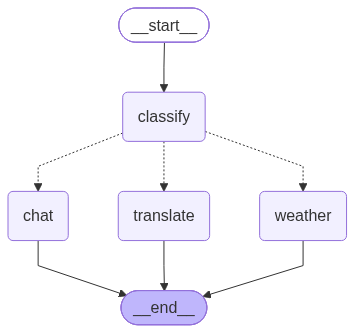

'今天北京天气如何？' -> intent=weather -> 天气查询: 今天北京天气如何？ -> 晴 25度
'翻译hello' -> intent=translate -> 翻译: 翻译hello -> Hello World
'你好吗？' -> intent=chat -> 闲聊: 你好吗？ -> 你好呀！


In [1]:

from typing import Annotated, TypedDict, Literal, List
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import (
    BaseMessage, SystemMessage, HumanMessage, ToolMessage
)
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from IPython.display import Image, display
from operator import add
from dotenv import load_dotenv
from pydantic.dataclasses import dataclass
from pydantic import BaseModel, Field

load_dotenv()

# 定义作为路由逻辑的结构化输出模型
class Route(BaseModel):
    step: Literal["weather", "translate", "chat"] = Field(
        None, description="The next step in the routing process"
    )
def display_graph(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))

llm = init_chat_model("deepseek-chat")
# 把路由结构化输出绑定到模型，形成一个用于路由的llm
router = llm.with_structured_output(Route)

class IntentState(TypedDict):
    query: str
    intent: str
    result: str

def classify_intent(state: IntentState):
    """分类用户意图"""
    # Run the augmented LLM with structured output to serve as routing logic
    decision = router.invoke(
        [
            SystemMessage(
                content="Route the input to weather, translate, or chat based on the user's request."
            ),
            HumanMessage(content=state["query"]),
        ]
    )

    return {"intent": decision.step}

def handle_weather(state: IntentState):
    return {"result": f"天气查询: {state['query']} -> 晴 25度"}

def handle_translate(state: IntentState):
    return {"result": f"翻译: {state['query']} -> Hello World"}

def handle_chat(state: IntentState):
    return {"result": f"闲聊: {state['query']} -> 你好呀！"}

def intent_router(state: IntentState) -> Literal["weather", "translate", "chat"]:
    """根据意图路由到不同处理器"""
    return state["intent"]

routing_graph = (
    StateGraph(IntentState)
    .add_node("classify", classify_intent)
    .add_node("weather", handle_weather)
    .add_node("translate", handle_translate)
    .add_node("chat", handle_chat)
    .add_edge(START, "classify")
    .add_conditional_edges("classify", intent_router, {
        "weather": "weather",
        "translate": "translate",
        "chat": "chat"
    })
    .add_edge("weather", END)
    .add_edge("translate", END)
    .add_edge("chat", END)
    .compile()
)

display_graph(routing_graph)
for q in ["今天北京天气如何？", "翻译hello", "你好吗？"]:
    r = routing_graph.invoke({"query": q, "intent": "", "result": ""})
    print(f"'{q}' -> intent={r['intent']} -> {r['result']}")

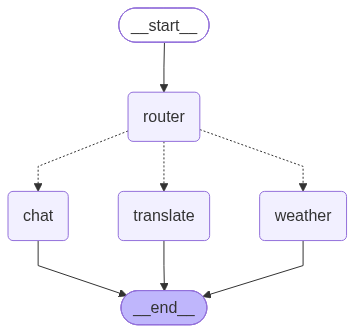

'今天北京天气如何？' -> intent=weather -> 天气查询: 今天北京天气如何？ -> 晴 25度
'翻译hello' -> intent=chat -> 闲聊: 翻译hello -> 你好呀！
'你好吗？' -> intent=chat -> 闲聊: 你好吗？ -> 你好呀！


In [4]:
from typing import Literal,TypedDict
from pydantic import BaseModel,Field
class qoto(BaseModel):
    step:Literal["chat","weather"]=Field(None,description="返回要跳转的节点")
class Custom(TypedDict):
    query:str
    intent:str
    result:str
from langchain.chat_models import init_chat_model
llm=init_chat_model("deepseek-chat")
llm_router=llm.with_structured_output(qoto)
from langchain_core.messages import  SystemMessage,HumanMessage
def router(state:Custom):
    '''结构化输出,更新用户意图'''
    response=llm_router.invoke(
        [SystemMessage(content="Route the input to weather, translate, or chat based on the user's request."),
         HumanMessage(content=state["query"])]
    )
    return {"intent":response.step}
def handle_weather(state: IntentState):
    return {"result": f"天气查询: {state['query']} -> 晴 25度"}

def handle_translate(state: IntentState):
    return {"result": f"翻译: {state['query']} -> Hello World"}

def handle_chat(state: IntentState):
    return {"result": f"闲聊: {state['query']} -> 你好呀！"}
def Router(state:Custom):
    '''根据用户的意图来决定下一步跳转的节点'''
    return state["intent"]
routing_graph2=(
    StateGraph(Custom)
    .add_node("router",router)
    .add_node("weather",handle_weather)
    .add_node("translate",handle_translate)
    .add_node("chat",handle_chat)
    .add_edge(START,"router")
    .add_conditional_edges("router",Router,{
        "weather":"weather",
        "translate":"translate",
        "chat":"chat"
    })
    .add_edge("weather",END)
    .add_edge("translate",END)
    .add_edge("chat",END)
    .compile()
)
def display_graph2(graph, xray=False):
    """显示图结构，xray=True 可展开子图内部结构"""
    display(Image(graph.get_graph(xray=xray).draw_mermaid_png()))
display_graph2(routing_graph2)
for q in ['今天北京天气如何？', '翻译hello', '你好吗？']:
    r=routing_graph2.invoke({"query":q,"intent":"","result":""})
    print(f"'{q}' -> intent={r['intent']} -> {r['result']}")


















